#$SIMULACION$ $DE$ $MONTECARLO$ para un $PLAN$ $DE$ $RETIRO$

Este cuaderno estima **cuánto dinero podrías tener al retirarte** si inviertes cada mes.



## ¿Qué es una $SIMULACION$ $DE$ $MONTECARLO$?

Nadie sabe cuánto va a rendir una inversión cada año. Algunos años rinde mucho y otros pierde.
En lugar de adivinar **un solo futuro**, la simulación de Montecarlo hace esto:

1. Inventa un año de rendimientos al azar (con un promedio y una variación realistas).
2. Repite eso año tras año hasta la edad de retiro. Eso es **un futuro posible**.
3. Repite todo miles de veces.

Al final no tenemos una sola respuesta, sino **muchos futuros posibles**, y podemos decir cosas como:
*"En la mitad de los casos termino con al menos X pesos"*.

## 1. Importar librerías

1.   Elemento de lista

In [17]:
# numpy: sirve para hacer cálculos con muchos números a la vez y generar números aleatorios
import numpy as np

# matplotlib: sirve para hacer gráficas
import matplotlib.pyplot as plt

# Fijamos una "semilla" para que el azar sea repetible:
# así, cada vez que ejecutes el cuaderno obtendrás los mismos resultados.
# Si quieres resultados distintos en cada ejecución, borra esta línea.
np.random.seed(42)

## 2. Parámetros (aquí PUEDES CAMBIAR tus datos)

Todos los montos están en **pesos de hoy** (ya descontando la inflación).

In [18]:
# Datos de la persona
edad_actual = 25            # Tu edad hoy
edad_retiro = 65            # Edad a la que quieres retirarte
saldo_inicial = 50_000      # Dinero que ya tienes ahorrado hoy (pesos)
aportacion_mensual = 3_000  # Cuánto inviertes cada mes (pesos)

# Supuestos del mercado
rendimiento_anual = 0.10    # Rendimiento promedio esperado por año (0.10 = 10 %)
volatilidad_anual = 0.15    # Qué tanto "se mueve" el rendimiento cada año (0.15 = 15 %)
inflacion_anual = 0.04      # Inflación promedio esperada (0.04 = 4 %)

# Simulación
numero_simulaciones = 10_000  # Cuántos futuros posibles vamos a simular

# Meta
meta = 5_000_000            # Dinero que te gustaría tener al retirarte (pesos de hoy)

## $3.$ $La$ $lógica$ $del$ $modelo$

Para cada año simulado hacemos tres cosas:

1. **Sumamos tus** `APORTACIONES` del año (`12 MESES` $x$ `APORTACION MENSUAL`).
2. **Sacamos un** $RENDIMIENTO$ `AL AZAR` con una distribución normal
   ($PROMEDIO$ = `rendimiento_real`, $VARIACION$ = `volatilidad_anual`).
3. **Aplicamos el rendimiento** al saldo: `SALDO = SALDO * (1 + RENDIMIENTO)`.

**Sobre la $INFLACION$ y el rendimiento real:**

Para que todo quede en pesos de hoy, usamos el *rendimiento real*

##**¿Por qué no basta con el rendimiento?**

Si tu dinero crece 10 % pero los precios suben 4 %, no puedes comprar 10 % más cosas, porque todo se encareció. Por eso, para saber cuánto crece realmente tu poder de compra, usamos el *rendimiento real*.

#**$Ejemplo$ ($En$ $pesos$)**
Hoy tienes $100$ y un producto cuesta $100$
1. Inviertes y rinde 10 %, así que en un año tienes $110$.
2. La inflación fue de 4 %, así que el producto ahora cuesta $104$.
3. Ahora puedes comprar 110 / 104 = 1.0577 productos.

Antes comprabas 1 producto y ahora 1.0577, así que tu poder de compra creció **5.77 %**, no 10 %.

Formulas:

`rendimiento_real = (1 + rendimiento_anual) / (1 + inflacion_anual) - 1`

##Con los $números$ $del$ $ejemplo$:

`rendimiento_real = (1 + 0.10) / (1 + 0.04) - 1 = 1.10 / 1.04 - 1 = 0.0577` (5.77 %)

- `(1 + rendimiento_anual)` es cuántas veces se multiplicó tu dinero.
- `(1 + inflacion_anual)` es cuántas veces se multiplicaron los precios.
- Al dividirlos comparamos las dos cosas.
- El `- 1` convierte el resultado de "1.0577 veces" a "5.77 %".

Así, si el dinero rinde 10 % pero los precios suben 4 %, tu poder de compra crece cerca de 5.8 %.

In [19]:
def simular_retiro(saldo_inicial, aportacion_mensual, anios,
                   rendimiento_anual, volatilidad_anual, inflacion_anual,
                   numero_simulaciones):
    """
    Simula muchas trayectorias posibles del saldo de retiro.

    Devuelve una tabla (matriz) donde:
      - cada FILA es un futuro posible (una simulación)
      - cada COLUMNA es un año (columna 0 = hoy, columna `anios` = retiro)
    """

    # Pasamos el rendimiento a "real" (descontando inflación)
    rendimiento_real = (1 + rendimiento_anual) / (1 + inflacion_anual) - 1
    #Con números: `(1 + 0.10) / (1 + 0.04) - 1 = 0.0577`.

    # Aportación de todo el año (12 meses). Supuesto simple: se aporta al inicio del año.
    aportacion_anual = aportacion_mensual * 12
    #Si aportas $3,000 al mes, en un año aportas 3,000 × 12 = **$36,000**.

    # Matriz de ceros donde iremos guardando el saldo de cada simulación en cada año
    saldos = np.zeros((numero_simulaciones, anios + 1))
    """
    - np.zeros(...)` crea una **tabla LLENA DE CEROS**.
    - **¿Por qué dos paréntesis `((` `))`?** El de afuera es el de la función. El de adentro AGRUPA **(FILAS, COLUMNAS)** como un solo dato.
    - `anios + 1` porque necesitamos una columna para el año 0 (HOY) y una por cada año HASTA EL RETIRO.

    Ejemplo con 3 simulaciones y 2 años (3 columnas):
            año 0   año 1   año 2
simulación 0 [ 0       0       0 ]
simulación 1 [ 0       0       0 ]
simulación 2 [ 0       0       0 ]
- Cada **FILA** es un FUTURO POSIBLE.
- Cada **COLUMNA** es UN AÑO.
    """

    # En el año 0 todas las simulaciones empiezan con el mismo saldo inicial
    saldos[:, 0] = saldo_inicial
    """Dentro de `[ ]` va **[FILAS, COLUMNAS]**
    Significa:
    | `:` | **TODAS** (TODAS LAS FILAS) |
    | `0` | La columna número 0 |
Entonces `saldos[:, 0]` quiere decir: *"TODAS LAS SIMULACIONES EN EL AÑO 0"*.

**Aquí `=` guarda el saldo inicial en toda esa columna, porque todos los futuros empiezan con el mismo dinero.

**Importante:** Python empieza a contar desde **0**, no desde 1. La primera columna es la 0.
    """

    # Generamos TODOS los rendimientos aleatorios de una vez:
    # una tabla con un rendimiento al azar por cada simulación y por cada año.
    rendimientos = np.random.normal(rendimiento_real, volatilidad_anual,
                                    size=(numero_simulaciones, anios))
    #Ejemplo de una fila: `[ +0.20, -0.08, +0.04, ... ]`, un rendimiento al azar para cada año.
    """
    - `np.random.normal(promedio, variación, ...)` genera números AL AZAE que quedan **CERCA DEL PROMEDIO**
    - `size=(...)` dice **CUANTOS** números queremos: una tabla de (simulaciones × años).
    """

    # Recorremos los años uno por uno
    for anio in range(1, anios + 1):
        # 1) Saldo del año anterior + aportaciones de este año
        saldo_con_aportacion = saldos[:, anio - 1] + aportacion_anual
        #- "saldos[:, anio - 1]" = "todas las simulaciones, en el año **ANTERIOR**".
        #- Le sumamos lo que aportas en el año.
        """
        Saldo del año anterior $100,000 + aportación del año $36,000 → $136,000.
        Saldo_con_aportacion = 100,000 + 36,000 = 136,000

        Ese resultado ($136,000) es el que se multiplica por `(1 + rendimiento)` en el paso 2.
        """

        # 2) Aplicamos el rendimiento aleatorio de este año
        saldos[:, anio] = saldo_con_aportacion * (1 + rendimientos[:, anio - 1])
        """
        Ejemplo:
        $136,000 con un rendimiento de 8 % → 136,000 × 1.08 = $146,880.

        saldo_con_aportacion = 100,000 + 36,000 = 136,000
        saldo nuevo          = 136,000 * (1 + 0.08) = 146,880

        El año siguiente empieza con $146,880 y se repite el proceso.

        ¿Por qué `anio - 1` en `rendimientos`?
        **Porque esa tabla no tiene columna del año 0, así que el año 1 está en la columna 0, el año 2 en la columna 1, y así.

        `saldos[:, anio] = ...` **guarda** el resultado en la columna del año actual.
        """

        # 3) El saldo nunca puede ser negativo (en el peor caso, se pierde todo)
        saldos[:, anio] = np.maximum(saldos[:, anio], 0)
        # Si el saldo saliera -500, se convierte en 0. En la vida real no puedes tener menos de cero ahorrado.
        """
        Ejemplo:
        Si después del paso 2 el saldo sale en **-$10,000**, `np.maximum` lo cambia a **$0**.

       saldo nuevo = 50,000 * (1 + (-1.20)) = -10,000
       np.maximum(-10,000, 0) = 0

       Si el saldo sale positivo, se queda igual:

       np.maximum(146,880, 0) = 146,880
       `saldos[:, anio] = ...` **guarda** el resultado ya corregido en la columna del año actual.

        """

    return saldos

## 4. Ejecutar la simulación

In [20]:
# Cuántos años faltan para el retiro
anios = edad_retiro - edad_actual

# Corremos la simulación con los parámetros de arriba
saldos = simular_retiro(saldo_inicial, aportacion_mensual, anios,
                        rendimiento_anual, volatilidad_anual, inflacion_anual,
                        numero_simulaciones)

# El saldo final de cada simulación es la última columna
saldos_finales = saldos[:, -1]

print(f"Se simularon {numero_simulaciones:,} futuros posibles a {anios} años.")

Se simularon 10,000 futuros posibles a 40 años.


## 5. Resultados

Los $PERCENTILES$ nos dicen en **cuántos casos se cumple algo**.
Por ejemplo, el percentil 50 (la mediana) significa: `"EN la MITAD de los futuros terminé CON MAS que esto y en la otra mitad con MENOS"`.

In [21]:
# Percentiles que queremos mostrar
percentiles = [5, 25, 50, 75, 95]
valores = np.percentile(saldos_finales, percentiles)
"""
Ejemplo de lo que contienen:
```
percentiles = [5,        25,        50,        75,        95        ]
valores     = [1,651,468 3,049,486  4,787,629  7,579,823  14,672,008]
```
El percentil 5 significa: "solo el 5 % de los futuros terminó con menos que esto".
"""

descripciones = {
    5:  "Escenario malo (solo 5 % de los casos es peor)",
    25: "Escenario conservador",
    50: "Escenario típico (mediana)",
    75: "Escenario favorable",
    95: "Escenario muy bueno (solo 5 % de los casos es mejor)",
}

print(f"Saldo al retiro (a los {edad_retiro} años), en pesos de hoy:\n")
# Ejemplo, con `edad_retiro = 65`:
# Saldo al retiro (a los 65 años), en pesos de hoy:
for p, v in zip(percentiles, valores):
  """
  `zip(a, b)` **junta dos listas en PAREJAS**.
  `for p, v in ...` toma una pareja en cada vuelta: `p` es el PERCENTIL y `v` es su VALOR.

Las parejas que forma `zip`:
```
vuelta 1:  p = 5    v = 1,651,468
vuelta 2:  p = 25   v = 3,049,486
vuelta 3:  p = 50   v = 4,787,629
vuelta 4:  p = 75   v = 7,579,823
vuelta 5:  p = 95   v = 14,672,008
"""
  print(f"Percentil {p:>2}: ${v:>10,.0f}  -> {descripciones[p]}")
  """
Qué hace ?
| `{descripciones[p]}` | Busca en el diccionario el texto que corresponde a `p`
  """
  #Ejemplo: Percentil  5: $ 1,651,468  -> Escenario malo (solo 5 % de los casos es peor)
  """
| `->` | Es solo una flecha hecha con dos símbolos, para que se vea ordenado |
  """
# Total que pondrías de tu bolsillo (sin contar rendimientos), para comparar
total_aportado = saldo_inicial + aportacion_mensual * 12 * anios

#Ejemplo con saldo inicial de $50,000, aportación de $3,000 al mes y 40 años:
"""
aportacion_mensual * 12 * anios = 3,000 * 12 * 40 = 1,440,000
total_aportado = 50,000 + 1,440,000 = 1,490,000
Son los 12 meses de cada año, durante 40 años.
"""

print(f"\nTotal que aportarías de tu bolsillo: ${total_aportado:,.0f}")

Saldo al retiro (a los 65 años), en pesos de hoy:

Percentil  5: $ 1,651,468  -> Escenario malo (solo 5 % de los casos es peor)
Percentil 25: $ 3,049,486  -> Escenario conservador
Percentil 50: $ 4,787,629  -> Escenario típico (mediana)
Percentil 75: $ 7,579,823  -> Escenario favorable
Percentil 95: $14,672,008  -> Escenario muy bueno (solo 5 % de los casos es mejor)

Total que aportarías de tu bolsillo: $1,490,000


In [31]:
# Probabilidad de llegar a la meta:
# El promedio de esos True/False es la proporción de veces que se cumplió.
probabilidad_meta = np.mean(saldos_finales >= meta)
"""
`saldos_finales` tiene el saldo final de cada simulación. Al compararlo con `META`, Python responde **True** (VERDADERO) o **False** (FALSO) para CADA SIMULACION.

Ejemplo con 5 simulaciones y una meta de $5,000,000:

saldos_finales = [6,200,000   3,100,000   5,000,000   4,800,000   8,900,000]
saldos_finales >= META
               = [True        False       True        False       True     ]

- 6,200,000 es mayor que la meta, así que es **TRUE**.
- 3,100,000 es menor, así que es **FALSE**.
- 5,000,000 es igual a la meta, y como usamos `>=` (que incluye el igual), es **True**.
"""

#3. El promedio de True y False: `np.mean`
#probabilidad_meta = np.mean(saldos_finales >= meta)

"""
Para Python, **TRUE vale 1 y FALSE vale 0**.
"""
#`np.mean` saca el **PROMEDIO**: suma todos los valores y los divide entre cuántos son.

"""
Ejemplo:
[True  False  True  False  True]  →  [1  0  1  0  1]

promedio = (1 + 0 + 1 + 0 + 1) / 5 = 3 /

3 de 5 simulaciones llegaron a la meta.
Es decir, el **60 %**. Por eso el promedio de True/False es la proporción de veces que se cumplió la meta.
"""

#En la simulación real son 10,000 futuros. Si 4,740 llegaron a la meta:
#probabilidad_meta = 4,740 / 10,000 = 0.474

print(f"Meta: ${meta:,.0f}")
print(f"Probabilidad de alcanzarla: {probabilidad_meta:.1%}")

#La **`f`** antes de las comillas crea un *f-string*: un texto donde lo que está entre `{ }` se **sustituye por el valor de una variable**.
#El **`$`** aquí es solo el signo de pesos, un carácter normal. Lo que Python sustituye es lo que está entre llaves `{ }`.

### El formato `{meta:,.0f}`
"""
Qué hace?
| `,` | Pone **comas DE MILES**
| `.0f` | Muestra **0 decimales** (la `f` es por número con decimales)

Ejemplo:
meta = 5000000
{meta}         →  5000000
{meta:,.0f}    →  5,000,000
"""

###El formato `{probabilidad_meta:.1%}`
"""
Qué hace?

| `%` | **Multiplica por 100** y agrega el signo `%`
| `.1` | Muestra **1 decimal**

Ejemplo:
probabilidad_meta = 0.474
{probabilidad_meta:.1%}  →  47.4%

Esto significa que, en 47.4 % de los futuros simulados, el saldo al retiro ALCANZA o SUPERA la meta.
"""
# Fin de la celda (evita que se imprima la explicación de arriba)
pass

Meta: $5,000,000
Probabilidad de alcanzarla: 47.4%


## 6. Gráficas

**Gráfica 1 – Abanico de trayectorias:** muestra cómo crece el dinero con el tiempo.
La línea central es el caso típico y las franjas muestran qué tan lejos pueden ir los casos buenos y malos.

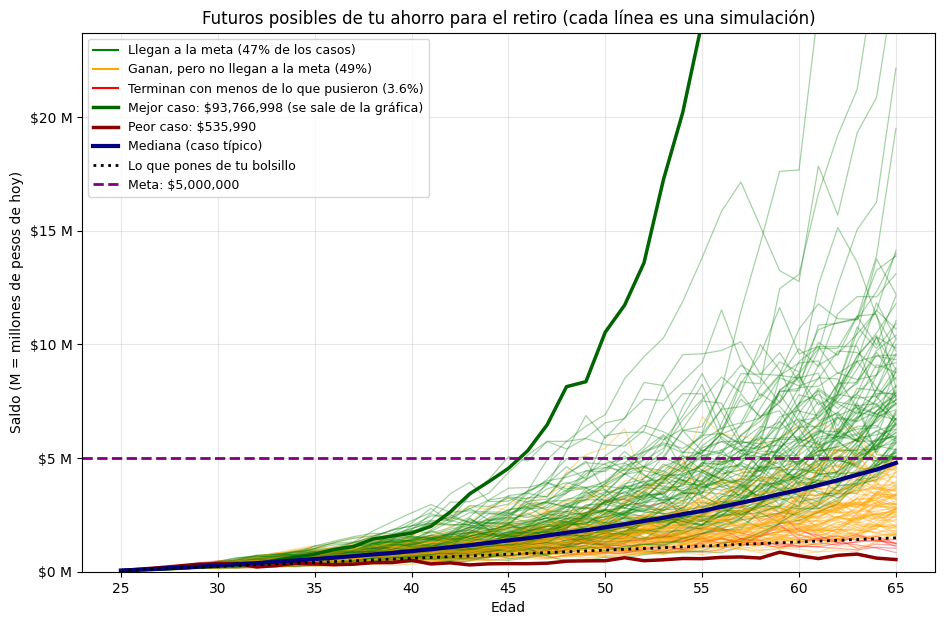

In [29]:
# Eje horizontal: la edad en cada año de la simulación
edades = np.arange(edad_actual, edad_retiro + 1)

# Dinero que pondrías de tu bolsillo en total (sin contar rendimientos)
total_aportado = saldo_inicial + aportacion_mensual * 12 * anios

# Lo que has puesto de tu bolsillo año por año (una línea recta que sube poco a poco)
aportado_por_anio = saldo_inicial + aportacion_mensual * 12 * np.arange(0, anios + 1)

# Mediana de cada año (axis=0 = calculamos hacia abajo, por columna)
p50 = np.percentile(saldos, 50, axis=0)

# ---------- Clasificamos TODAS las simulaciones según cómo terminaron ----------
pct_meta = np.mean(saldos_finales >= meta)                 # llegaron a la meta
pct_perdida = np.mean(saldos_finales < total_aportado)     # terminaron con menos de lo que pusieron
pct_medio = 1 - pct_meta - pct_perdida                     # el resto: ganaron, pero sin llegar a la meta

plt.figure(figsize=(11, 7))

# Elegimos 200 simulaciones al azar para dibujarlas (dibujar las 10,000 sería muy pesado)
indices = np.random.choice(numero_simulaciones, size=200, replace=False)

# Dibujamos cada trayectoria con un color según cómo terminó
for i in indices:
    saldo_final = saldos[i, -1]
    if saldo_final >= meta:
        color = "green"        # sube muchísimo: llega a la meta
    elif saldo_final >= total_aportado:
        color = "orange"       # gana, pero no llega a la meta
    else:
        color = "red"          # termina con menos dinero del que puso
    plt.plot(edades, saldos[i], color=color, alpha=0.35, linewidth=0.9)

# Líneas "falsas" (vacías) solo para que aparezcan en la leyenda con su color
plt.plot([], [], color="green",  label=f"Llegan a la meta ({pct_meta:.0%} de los casos)")
plt.plot([], [], color="orange", label=f"Ganan, pero no llegan a la meta ({pct_medio:.0%})")
plt.plot([], [], color="red",    label=f"Terminan con menos de lo que pusieron ({pct_perdida:.1%})")

# Mejor y peor caso de las 10,000 simulaciones (argmax/argmin dan la posición del mayor/menor)
mejor = np.argmax(saldos_finales)
peor = np.argmin(saldos_finales)
plt.plot(edades, saldos[mejor], color="darkgreen", linewidth=2.5,
         label=f"Mejor caso: ${saldos_finales[mejor]:,.0f} (se sale de la gráfica)")
plt.plot(edades, saldos[peor], color="darkred", linewidth=2.5,
         label=f"Peor caso: ${saldos_finales[peor]:,.0f}")

# Mediana, dinero aportado y meta
plt.plot(edades, p50, color="navy", linewidth=3, label="Mediana (caso típico)")
plt.plot(edades, aportado_por_anio, color="black", linestyle=":", linewidth=2,
         label="Lo que pones de tu bolsillo")
plt.axhline(meta, color="purple", linestyle="--", linewidth=2, label=f"Meta: ${meta:,.0f}")

# Mostramos el eje vertical en millones (ej. "$5 M") en vez de notación científica (ej. 1e7)
plt.gca().yaxis.set_major_formatter(lambda valor, posicion: f"${valor / 1_000_000:,.0f} M")

# Limitamos el eje vertical para que el mejor caso (muy grande) no aplaste al resto
plt.ylim(0, np.percentile(saldos_finales, 99))

plt.title("Futuros posibles de tu ahorro para el retiro (cada línea es una simulación)")
plt.xlabel("Edad")
plt.ylabel("Saldo (M = millones de pesos de hoy)")
plt.legend(loc="upper left", fontsize=9)
plt.grid(alpha=0.3)
plt.show()

## 7. Puedes experimentar

Cambia los parámetros de la sección 2 y vuelve a ejecutar todo:

#**Limitaciones del modelo**

- **Cada año es independiente.** Un buen año no influye en cómo será el siguiente. En la realidad, los mercados a veces sí se arrastran de un año a otro.
- **Los rendimientos siguen una distribución normal:** la mayoría salen cerca del promedio y pocos salen muy lejos. En la vida real, las caídas fuertes pueden ser más frecuentes que en este modelo.
- **El rendimiento promedio, la variación y la inflación son los mismos todos los años.** En la realidad cambian.
- **La aportación es constante en pesos de hoy** y se hace al inicio de cada año.
- **No incluye impuestos ni comisiones**, que bajarían el resultado final.
- **Solo simula hasta la edad de retiro.** No modela cuánto dinero se gasta después de retirarse.
- **Los datos (edad, aportación, rendimiento, meta)** Se pueden cambiar en la sección de Parámetros.

Es una herramienta para entender escenarios posibles, no una predicción ni una recomendación financiera.